## Library Importation

In [1]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Data Loading from UCI Repository

In [2]:

columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

data = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None, names=columns, na_values=" ?"
)

for col in data.select_dtypes(include=["object"]).columns:
    
    data[col] = data[col].str.strip()

## Select 10 variables of interest

In [3]:
numeric_features = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]

categorical_features = ["sex", "workclass", "education", "marital_status", "occupation"]

selected_features = numeric_features + categorical_features

X = data[selected_features].copy()

y = (data["income"] == ">50K").astype(int)   

## Predicting Adult Income Over $50K

In [4]:
print("Full dataset:", data.shape)
print("Selected data:", X.shape)
print("Target:", y.shape)
X.head()

Full dataset: (32561, 15)
Selected data: (32561, 10)
Target: (32561,)


,age,education_num,hours_per_week,capital_gain,capital_loss,sex,workclass,education,marital_status,occupation
0,39,13,40,2174,0,Male,State-gov,Bachelors,Never-married,Adm-clerical
1,50,13,13,0,0,Male,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial
2,38,9,40,0,0,Male,Private,HS-grad,Divorced,Handlers-cleaners
3,53,7,40,0,0,Male,Private,11th,Married-civ-spouse,Handlers-cleaners
4,28,13,40,0,0,Female,Private,Bachelors,Married-civ-spouse,Prof-specialty


## Check the Data

I checked the data types, missing values and exact duplicate rows before cleaning.

In [5]:
# Summarise the selected columns
data_quality = pd.DataFrame({
    "Data type": X.dtypes.astype(str),
    "Missing values": X.isna().sum(),
    "Missing (%)": (X.isna().mean() * 100).round(2)
})

print(data_quality)

print("\nDuplicate rows across all original columns:", data.duplicated().sum())
print(
    "Repeated combinations of selected features and income:",
    data.duplicated(subset=selected_features + ["income"]).sum()
)
print(
    "Rows with at least one missing selected feature:",
    X.isna().any(axis=1).sum()
)

               Data type  Missing values  Missing (%)
age                int64               0         0.00
education_num      int64               0         0.00
hours_per_week     int64               0         0.00
capital_gain       int64               0         0.00
capital_loss       int64               0         0.00
sex                  str               0         0.00
workclass            str            1836         5.64
education            str               0         0.00
marital_status       str               0         0.00
occupation           str            1843         5.66

Duplicate rows across all original columns: 24
Repeated combinations of selected features and income: 5864
Rows with at least one missing selected feature: 1843


### Duplicate Rows

There were 24 duplicate rows, so I removed them and kept the first copy. Another 5,864 rows share the same selected features and income, but they may differ in other columns, so I kept them, rows with missing values were also kept. The model pipeline fills those values later.

In [6]:
# Remove exact duplicate rows
data_clean = data.drop_duplicates(keep="first", ignore_index=True)

# Rebuild X and y from the cleaned data
X = data_clean[selected_features].copy()
y = (data_clean["income"] == ">50K").astype(int)

# Check the cleanup
print("Original number of rows:", len(data))
print("Duplicate rows removed:", len(data) - len(data_clean))
print("Remaining number of rows:", len(data_clean))
print("Remaining exact duplicates:", data_clean.duplicated().sum())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print(
    "\nRows with missing selected features:",
    X.isna().any(axis=1).sum()
)

Original number of rows: 32561
Duplicate rows removed: 24
Remaining number of rows: 32537
Remaining exact duplicates: 0

Features shape: (32537, 10)
Target shape: (32537,)

Rows with missing selected features: 1843


## Explore the Data

I looked at summary statistics and plots for income, age, education and weekly hours.

In [7]:
X[numeric_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32537.0,38.59,13.64,17.0,28.0,37.0,48.0,90.0
education_num,32537.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
hours_per_week,32537.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0
capital_gain,32537.0,1078.44,7387.96,0.0,0.0,0.0,0.0,99999.0
capital_loss,32537.0,87.37,403.10,0.0,0.0,0.0,0.0,4356.0


In [8]:
class_distribution = pd.DataFrame({"Count": y.value_counts().sort_index()})
class_distribution["Percentage (%)"] = (class_distribution["Count"] / len(y) * 100).round(2)
class_distribution.index = ["<=50K", ">50K"]
class_distribution.index.name = "Income class"
class_distribution

,Count,Percentage (%)
Income class,,
<=50K,24698,75.91
>50K,7839,24.09


### Main Findings

The income groups are uneven 75.91% earn <=50K and 24.09% earn >50K, so accuracy alone may not tell the full story, a
average age is 38.59 years (median 37), and the average work week is 40.44 hours (median 40). At least 75% of records have zero capital gain and loss; a few large values pull the averages up.

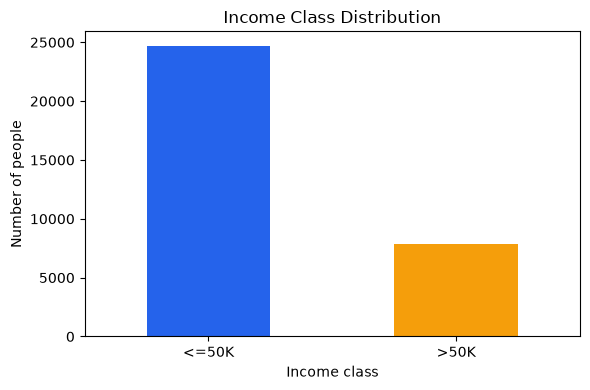

In [9]:
ax = class_distribution["Count"].plot(
    kind="bar", color=["#2563EB", "#F59E0B"], figsize=(6, 4)
)
ax.set_title("Income Class Distribution")
ax.set_xlabel("Income class")
ax.set_ylabel("Number of people")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

Boxplots: age, education and weekly hours by income group.

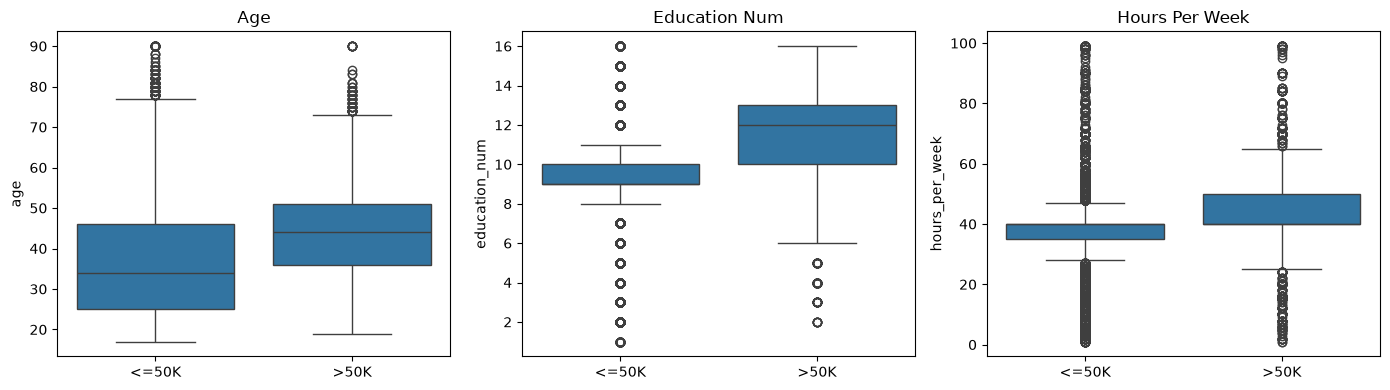

In [10]:
eda_data = X[["age", "education_num", "hours_per_week"]].copy()
eda_data["Income class"] = y.map({0: "<=50K", 1: ">50K"})

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, ["age", "education_num", "hours_per_week"]):
    sns.boxplot(data=eda_data, x="Income class", y=feature, ax=ax)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

People earning >50K have higher median age and education numbers. Both groups have a 40-hour median week, but the >50K group has more values above 40. The boxes overlap, so the groups are not fully separate, these plots show links not causes.

## Split the Data

I used 80% of the data for training and 20% for testing. Stratifying the split keeps the income groups in similar proportions, and the fixed seed makes it repeatable. The test set is saved for the final check.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 26029
Test rows: 6508


## Prepare the Data

Missing numbers are filled with the training median, and missing categories with the most common training value. Categories are one-hot encoded, new categories at prediction time are ignored, number features are scaled with StandardScaler. Keeping these steps in each pipeline means they are learned from the training data in each fold.

In [12]:
numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, numeric_features),
    ("categorical", categorical_steps, categorical_features)
])
print("Preprocessing is ready.")

Preprocessing is ready.


## Compare the First Models

I used Logistic Regression as the baseline and compared it with an untuned Random Forest using five-fold stratified cross-validation on the training data. Each model has its own preprocessing steps. I report accuracy, precision, recall, F1-score and ROC-AUC; precision, recall and F1-score refer to the >50K group. The test set is saved for the final check.

In [13]:
logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

In [14]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline
}
cv_rows = {}

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {
        metric: scores[f"test_{metric}"].mean() for metric in scoring
    }
    cv_rows[name]["F1 std"] = scores["test_F1"].std()

cv_comparison = pd.DataFrame(cv_rows).T.sort_values("F1", ascending=False)
cv_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,F1 std
Random Forest,0.8416,0.6916,0.6181,0.6527,0.8888,0.0165
Logistic Regression,0.8483,0.7309,0.5860,0.6505,0.9011,0.0058


### First Results

Logistic Regression had higher mean accuracy, precision and ROC-AUC. Random Forest had higher recall and a slightly higher F1-score (0.6527 vs. 0.6505), but its F1-score changed more across folds. The difference is small, so I tuned the Random Forest before the final test.

## Tune the Random Forest

GridSearchCV checks 12 combinations of tree depth, minimum samples per leaf and class weights. It uses five-fold stratified cross-validation, with 200 trees in each model. I chose the setup with the best average F1-score for the >50K group. The search uses training data only and then fits the best setup on all the training data.

In [15]:
param_grid = {
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid, scoring=scoring, refit="F1", cv=cv,
    return_train_score=True
)
print("Grid search is ready.")

Grid search is ready.


In [16]:
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_

print("Best settings:", grid_search.best_params_)
print(f"Best validation F1: {grid_search.best_score_:.4f}")

results = pd.DataFrame(grid_search.cv_results_)
results[["params", "mean_train_F1", "mean_test_F1"]].sort_values(
    "mean_test_F1", ascending=False
).head().round(4)

Best settings: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1}
Best validation F1: 0.6908


,params,mean_train_F1,mean_test_F1
10,"{'classifier__class_weight': 'balanced', 'clas...",0.8213,0.6908
7,"{'classifier__class_weight': 'balanced', 'clas...",0.7252,0.6904
11,"{'classifier__class_weight': 'balanced', 'clas...",0.7168,0.6866
8,"{'classifier__class_weight': 'balanced', 'clas...",0.6990,0.6767
1,"{'classifier__class_weight': None, 'classifier...",0.7195,0.6757


### Tuning Results

The best Random Forest scored 0.6908 on validation, with 200 trees, a maximum depth of 20, one sample per leaf and balanced class weights. This is higher than the first Random Forest score of 0.6527, but the training score of 0.8213 suggests it fits the training data better than new data. The second-best setup scored almost the same at 0.6904, so the gap is small. I kept the top setup by validation F1-score and checked it on the test data.

## Test Set Results

I tested Logistic Regression, the first Random Forest and the tuned Random Forest on the same test data. All models were fitted using the training data. I did not use the test results to tune them.

In [17]:
logistic_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

final_models = {
    "Logistic Regression": logistic_pipeline,
    "Initial Random Forest": rf_pipeline,
    "Tuned Random Forest": best_rf
}
print("Models are ready for the test set.")

Models are ready for the test set.


In [18]:
test_predictions = {}
test_probabilities = {}
rows = {}

for name, model in final_models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = prediction
    test_probabilities[name] = probability
    rows[name] = {
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1": f1_score(y_test, prediction),
        "ROC_AUC": roc_auc_score(y_test, probability)
    }

test_results = pd.DataFrame(rows).T
test_results.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.8563,0.7471,0.6103,0.6718,0.9076
Initial Random Forest,0.8479,0.7079,0.6276,0.6653,0.8921
Tuned Random Forest,0.8245,0.5942,0.8571,0.7018,0.9179


### Model Comparison

The tuned Random Forest had the best test F1-score (0.7018), recall (0.8571) and ROC-AUC (0.9179). Logistic Regression had higher accuracy (0.8563) and precision (0.7471). The tuned Random Forest found more of the >50K group, but it also made more false positive predictions.

### Confusion Matrices

These charts show correct and incorrect predictions for each model. Rows show the actual income group; columns show the predicted group.

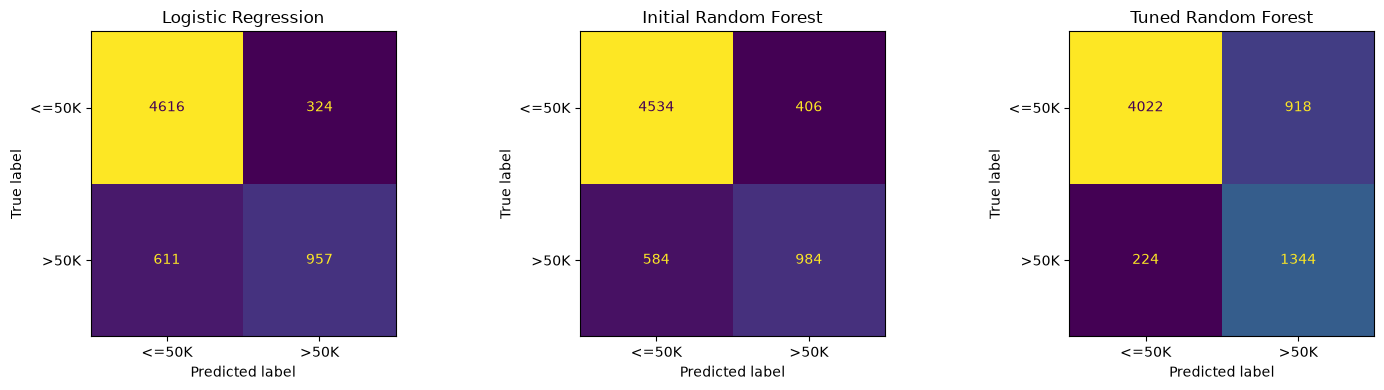

,True negatives,False positives,False negatives,True positives
Model,,,,
Logistic Regression,4616,324,611,957
Initial Random Forest,4534,406,584,984
Tuned Random Forest,4022,918,224,1344


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
confusion_rows = []

for ax, (name, prediction) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, prediction)
    ConfusionMatrixDisplay(
        matrix, display_labels=["<=50K", ">50K"]
    ).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append([name, tn, fp, fn, tp])

plt.tight_layout()
plt.show()
confusion_summary = pd.DataFrame(
    confusion_rows,
    columns=["Model", "True negatives", "False positives", "False negatives", "True positives"]
).set_index("Model")
confusion_summary

### What the Confusion Matrices Show

The tuned Random Forest found the most people in the >50K group: 1,344 true positives and 224 false negatives. It also made the most false positive predictions (918). This gave it higher recall but lower precision. It may fit a task where missing a >50K case matters more than a false alarm.

### ROC Curves

The curves show how the true positive rate changes against the false positive rate at different cutoffs. ROC-AUC gives one score for how well a model ranks the two groups.

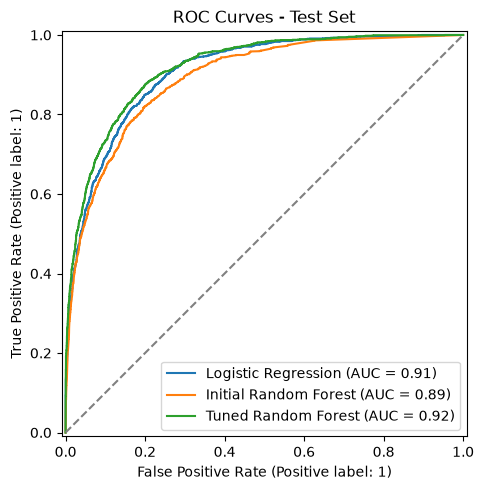

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, probability in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("ROC Curves - Test Set")
plt.tight_layout()
plt.show()

### ROC-AUC Results

The tuned Random Forest had the highest ROC-AUC (0.9179), followed by Logistic Regression (0.9076) and the first Random Forest (0.8921). This means it ranked the groups better overall, but it also made more false positives at the default cutoff. ROC-AUC should be read with precision, recall, F1-score and the confusion matrix.

## Model Interpretation

The chart below shows the five most important features in the tuned Random Forest. One-hot encoding gives each category its own feature.

In [21]:
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
forest = best_rf.named_steps["classifier"]
top_features = pd.Series(
    forest.feature_importances_, index=feature_names
).nlargest(5).sort_values() * 100
top_features.name = "Importance (%)"
top_features.index.name = "Feature"
top_features.round(2).to_frame()

,Importance (%)
Feature,
numeric__hours_per_week,9.21
numeric__capital_gain,9.46
numeric__education_num,9.54
numeric__age,16.27
categorical__marital_status_Married-civ-spouse,18.23


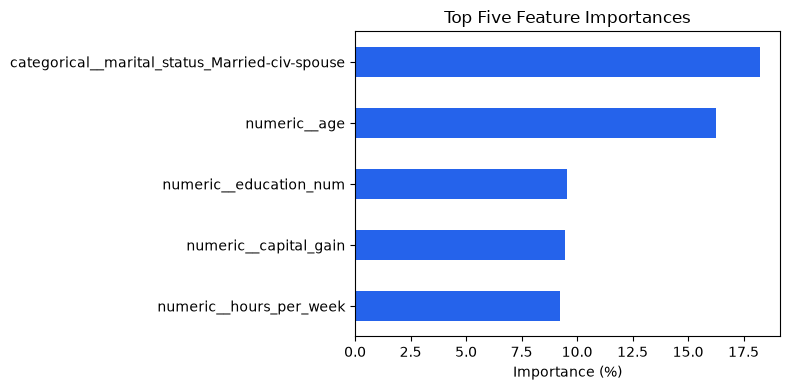

In [22]:
ax = top_features.plot(kind="barh", color="#2563EB", figsize=(8, 4))
ax.set_title("Top Five Feature Importances")
ax.set_xlabel("Importance (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Feature Importance

Marital status (Married-civ-spouse) ranked first at 18.23%, followed by age at 16.27%. Education, capital gain and weekly hours each scored about 9%. These scores show which inputs the model used most; they do not show that an input causes higher income. One original category can also appear as several features after one-hot encoding.

In [23]:
model_path = Path("model_deployment") / "adult.pkl"
model_path.parent.mkdir(exist_ok=True)
joblib.dump(best_rf, model_path)
print("Saved model to", model_path)

Saved model to model_deployment\adult.pkl


## Critical Discussion

The most useful inputs in my Random Forest were married-civ-spouse status, age, education, capital gain and weekly hours. This seems reasonable because work, schooling and experience are linked with income in this data. But the scores only show patterns the model found. They do not show that any one thing causes higher pay.

On the test set, the tuned Random Forest had the best F1-score (0.7018), recall (0.8571) and ROC-AUC (0.9179). Logistic Regression had higher accuracy and precision. The Forest found more >50K cases, but also give me more false positive predictions. The better choice depends on which kind of mistake matters more.

A bank should not let this model make a decision on its own. A staff member should check the result, and people should be able to challenge wrong information. The Adult data is old, so it may not match applicants today. Some features can also reflect social differences, if people trust the predictions without checking them, unfair patterns could continue or a person could lose a chance because of a wrong result. The bank would need to review the model and its effects regularly.

### Local Demo

I tried the Flask form with two example profiles. The first was predicted as <=50K, with a 0.235 probability of >50K; the second was predicted as >50K, with a 0.516 probability. Both returned a result through the form.